# Wir implementieren einen Hund-Katze Klassifikator mit neuronalen Netzen

In [2]:
!uv pip install scikit-learn opencv-python imutils matplotlib

Using Python 3.12.13 environment at: /home/yousef/dev_glob/ml2026/bocklet
Checked 4 packages in 6ms


In [3]:
import os

os.environ["CUDA_CACHE_PATH"] = os.path.expanduser("~/.nv/ComputeCache")
os.environ["CUDA_CACHE_MAXSIZE"] = str(8 * 1024**3)

import tensorflow as tf

gpus = tf.config.list_physical_devices("GPU")
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)

print("GPUs:", gpus)

I0000 00:00:1779269051.767785  256107 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1779269051.820924  256107 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE3 SSE4.1 SSE4.2 AVX AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1779269053.050452  256107 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


W0000 00:00:1779269054.638610  256107 gpu_device.cc:2458] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.


In [4]:
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Activation
from tensorflow.keras.optimizers import SGD
from tensorflow.keras.layers import Dense
from tensorflow.keras import utils
from imutils import paths
import numpy as np
import argparse
import cv2
import os
import tensorflow

## Folgende Funktion nimmt ein Bild entgegen, skaliert das Bild auf 32x32 RGB-Pixel, und liefert einen 3072-dim Merkmalevektor zurueck

In [5]:
def image_to_feature_vector(image, size=(32, 32)):
	# resize the image to a fixed size, then flatten the image into
	# a list of raw pixel intensities
    
    return cv2.resize(image, size).flatten()

## Laden Sie die Daten aus der FAUbox (https://faubox.rrze.uni-erlangen.de/getlink/fi2yLBetrDDZ5i2oa6wpUc/):

- data/train.zip

- data/test100.zip


Schreiben Sie eine Funktion, die die Bilder einliest und mit Hilfe der Funktion image_to_feature_vector vorverarbeiten. Anschließend sollen die Vektoren in eine data-Matrix geschrieben werden. 
Zusätzlich ist ein label-Vektor zu erzeugen. Wie sehen die Labels sinnvollerweise aus?

In [6]:

cwd = os.getcwd()
cwd

'/home/yousef/dev_glob/ml2026/10+11_NeuralNetsAndTraining/notebooks'

In [7]:
# "https://docs.opencv.org/4.x/d4/da8/group__imgcodecs.html"

os.chdir(cwd)
os.chdir("../data")
os.chdir("train")

data = np.ndarray((25_000, 3072))
labels = np.zeros(25000)

i = 0
for image_path in os.listdir():
    
    l = image_path.split(".")
    textual_label, number, ext = l[0], l[1], l[2]
    label = 0 if textual_label == "cat" else 1
    img_data = cv2.imread(image_path)
    feat_vec = image_to_feature_vector(img_data)
    data[i] = feat_vec
    labels[i] = label

    i+=1
    

os.chdir(cwd)

In [8]:
print(data.shape)

(25000, 3072)


ideas: 
* use bw info only
* split data into 3 per-channel matrices: i.e. RRR GGG BBB instead of RGB_1 RGB_2 RGB_3 ... RGB_N
* experiment with larger images

In [14]:
data_flat = data
data_list_pixel_vecs = data.reshape((data.shape[0], 1024, 3)) 
data_img2d = data.reshape((data.shape[0], 32, 32, 3))

# grayscale = 0.299 * r + 0.587 * g + 0.114 * b
grayscale = np.array([0.114, 0.587, 0.299]) # BGR
data_img2d_bw = data_img2d @ grayscale

[[173.769 184.965 195.965 ... 226.794 219.018 209.829]
 [172.834 181.606 190.606 ... 228.815 219.018 214.779]
 [172.834 180.606 182.606 ... 227.815 220.018 219.762]
 ...
 [138.969 141.969 140.73  ...   9.088   9.729   7.729]
 [134.072 138.969 141.958 ...   5.131   4.131   4.131]
 [127.702 133.371 140.958 ...   3.658   2.772   2.772]]


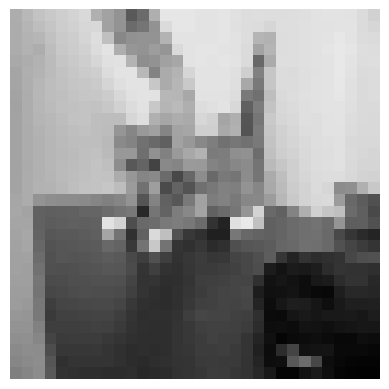

In [15]:
print(data_img2d_bw[0])

import numpy as np
import matplotlib.pyplot as plt

img = data_img2d_bw[0]

img_display = np.clip(img, 0, 255).astype(np.uint8)

plt.imshow(img_display, cmap="gray", vmin=0, vmax=255)
plt.axis("off")
plt.show()


cv2.imshow("image", np.clip(data_img2d[0], 0, 255).astype(np.uint8))
cv2.waitKey(0)
cv2.destroyAllWindows()

## Splitten Sie die Daten in ein train/test-set.

Macht es Sinn die Daten zu normieren?

In [10]:
RANDOM_STATE = 456

# Erstellen Sie ein Neuronales Netz mit Keras

Example Architecture: Overview
    
    * INPUT [32x32x3] will hold the raw pixel values of the image, in this case an image of width 32, height 32, and with three color channels R,G,B.
    
     * CONV layer will compute the output of neurons that are connected to local regions in the input, each computing a dot product between their weights and a small region they are connected to in the input volume. This may result in volume such as [32x32x12] if we decided to use 12 filters.
     
     * RELU layer will apply an elementwise activation function, such as the max(0,x) thresholding at zero. This leaves the size of the volume unchanged ([32x32x12]).
    
    * POOL layer will perform a downsampling operation along the spatial dimensions (width, height), resulting in volume such as [16x16x12].
   
    * FC (i.e. fully-connected) layer will compute the class scores, resulting in volume of size [1x1x10], where each of the 10 numbers correspond to a class score, such as among the 10 categories of CIFAR-10. As with ordinary Neural Networks and as the name implies, each neuron in this layer will be connected to all the numbers in the previous volume.

In [40]:
from tensorflow import keras

strides_hyper = (1, 1)

# When padding="same" and strides=1, the output has the same size as the input.
padding_hyper = "same" # or "valid" 

filters_hyper = 16

kernel_size_hyper = (3, 3)

groups_hyper = 1 

from keras.models import Sequential
from keras.layers import Reshape, Dense

model = Sequential()

conv_lay = keras.layers.Conv2D(
    filters=filters_hyper,
    kernel_size=kernel_size_hyper,
    strides=strides_hyper,
    padding=padding_hyper,
    data_format="channels_last", # (batch , height , width , channels)
    
    activation="relu", # max(0,x)
    
    use_bias=True,
    
    groups=groups_hyper,

    input_shape=(32, 32, 3) 
)

model.add(conv_lay)

model.add(Reshape((32 * 32, filters_hyper))) 

model.add(Dense(filters_hyper, activation="relu"))
model.add(keras.layers.Flatten())
model.add(Dense(1, activation="sigmoid"))

model.compile(
    loss="binary_crossentropy",
    optimizer="sgd",
    metrics=["accuracy"]
)

In [42]:
from sklearn.model_selection import train_test_split

train_split = 0.8

X_train, X_eval, y_train, y_eval = train_test_split(data_img2d, labels, train_size =train_split, test_size = 1- train_split, random_state = RANDOM_STATE, shuffle = True) 

model.fit(X_train, y_train, epochs=40, batch_size=128)

Epoch 1/40


I0000 00:00:1779274420.670833  280924 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_103473__.9


117/157 ━━━━━━━━━━━━━━━━━━━━ 0s 872us/step - accuracy: 0.5104 - loss: 0.6930

I0000 00:00:1779274421.643372  280927 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_103473__.9


157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.5008 - loss: 0.6931
Epoch 2/40
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 943us/step - accuracy: 0.5008 - loss: 0.6931
Epoch 3/40
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 961us/step - accuracy: 0.4967 - loss: 0.6931
Epoch 4/40
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 940us/step - accuracy: 0.5001 - loss: 0.6931
Epoch 5/40
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 950us/step - accuracy: 0.5009 - loss: 0.6931
Epoch 6/40
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 956us/step - accuracy: 0.4979 - loss: 0.6931
Epoch 7/40
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 994us/step - accuracy: 0.4991 - loss: 0.6931
Epoch 8/40
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 950us/step - accuracy: 0.5008 - loss: 0.6931
Epoch 9/40
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 947us/step - accuracy: 0.5009 - loss: 0.6931
Epoch 10/40
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 945us/step - accuracy: 0.4997 - loss: 0.6931
Epoch 11/40
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 967us/step - accuracy: 0.5001 - loss: 0.6931
Epoch 12/40
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s

# Evaluieren Sie das Netz auf den held-back Test-Daten


Berechnen Sie die Akkuratheit und die Verwechselungsmatrix

# Klassifizieren Sie zusätzlich die Daten aus test100 und schauen Sie sich die Ergebnisse an

# Verwenden Sie die Merkmalnormierungsmethoden und Testen Sie diese